# 🛡️ Phishing Website Detection — Machine Learning Pipeline

## Project Overview
Phishing is a social engineering cyberattack where malicious actors deploy counterfeit websites masquerading as trustworthy entities (banks, email providers, online stores) to steal sensitive credentials, financial data, and personal information.

This notebook implements an end-to-end Machine Learning pipeline using the **UCI Phishing Websites Dataset** (`data/phishing_data.csv`).

### Pipeline Roadmap:
1. **Exploratory Data Analysis (EDA):** Shape, column inspection, missing value verification, target distribution, and class balance.
2. **Correlation Analysis:** Pearson correlation matrix and annotated heatmap of top discriminating features.
3. **Data Preprocessing:** Feature-target separation, target encoding (0 = Phishing, 1 = Legitimate), and 80/20 stratified splitting.
4. **Model Training & Comparison:** Benchmarking **Logistic Regression**, **Random Forest**, and **XGBoost**.
5. **Evaluation Metrics:** Accuracy, Precision, Recall, F1-Score, and Confusion Matrices.
6. **Feature Importance:** Explaining the top cybersecurity indicators.
7. **Model Serialization:** Exporting the champion model to `model.pkl` for the Streamlit web application.


In [1]:
# Import required libraries
import os
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("✓ Libraries loaded successfully!")

✓ Libraries loaded successfully!


## 1. Exploratory Data Analysis (EDA)

We load the dataset from `data/phishing_data.csv` and inspect its shape, structure, and initial records.

> **Viva Note:** Always verify the dataset dimensions and inspect raw records before applying transformations to ensure no data corruption or encoding issues exist.


In [2]:
# Load the dataset from data/phishing_data.csv
data_path = 'data/phishing_data.csv'
df = pd.read_csv(data_path)

print(f"Dataset path: {data_path}")
print(f"Dataset Shape: {df.shape[0]} rows (samples) and {df.shape[1]} columns (features + target)")
df.head()

Dataset path: data/phishing_data.csv
Dataset Shape: 11055 rows (samples) and 32 columns (features + target)


,index,having_IPhaving_IP_Address,URLURL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,-1,-1,-1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,2,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,3,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,4,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,5,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1


### Column Names and Data Types Inspection
The UCI Phishing Websites dataset captures 30 discrete web-security heuristics extracted from URLs, HTML/JavaScript elements, and domain attributes, plus an `index` column and the target `Result`.


In [3]:
# Display column names and datatypes
print("--- Column Names ---")
for i, col in enumerate(df.columns, 1):
    print(f"{i:2d}. {col}")

print("\n--- Data Types Summary ---")
print(df.dtypes.value_counts())

--- Column Names ---
 1. index
 2. having_IPhaving_IP_Address
 3. URLURL_Length
 4. Shortining_Service
 5. having_At_Symbol
 6. double_slash_redirecting
 7. Prefix_Suffix
 8. having_Sub_Domain
 9. SSLfinal_State
10. Domain_registeration_length
11. Favicon
12. port
13. HTTPS_token
14. Request_URL
15. URL_of_Anchor
16. Links_in_tags
17. SFH
18. Submitting_to_email
19. Abnormal_URL
20. Redirect
21. on_mouseover
22. RightClick
23. popUpWidnow
24. Iframe
25. age_of_domain
26. DNSRecord
27. web_traffic
28. Page_Rank
29. Google_Index
30. Links_pointing_to_page
31. Statistical_report
32. Result

--- Data Types Summary ---
int64    32
Name: count, dtype: int64


### Missing Value Verification
Real-world datasets often have missing entries that necessitate imputation or dropping. We check if any missing values exist in this dataset.


In [4]:
# Check for missing / NaN values
missing_counts = df.isnull().sum()
total_missing = missing_counts.sum()

print(f"Total missing values: {total_missing}")
if total_missing == 0:
    print("✓ Dataset is clean: 0 missing or null values found across all features.")
else:
    print(missing_counts[missing_counts > 0])

Total missing values: 0
✓ Dataset is clean: 0 missing or null values found across all features.


### Target Class Distribution & Balance
In the UCI dataset:
- `-1`: **Phishing Website**
- `+1`: **Legitimate Website**

> **Viva Note:** Checking class balance is vital. Severe class imbalance requires resampling (SMOTE) or adjusted loss weights. If classes are reasonably balanced, standard stratified sampling and accuracy/F1 evaluation are reliable.


 Raw UCI Value      Class Name  Sample Count  Proportion (%)
             1 Legitimate (+1)          6157           55.69
            -1   Phishing (-1)          4898           44.31


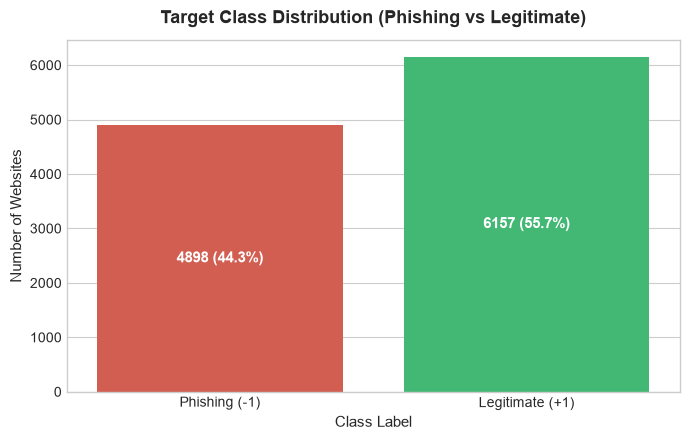

In [5]:
# Analyze class distribution
class_counts = df['Result'].value_counts()
class_pct = df['Result'].value_counts(normalize=True) * 100

summary_balance = pd.DataFrame({
    'Raw UCI Value': class_counts.index,
    'Class Name': ['Legitimate (+1)' if c == 1 else 'Phishing (-1)' for c in class_counts.index],
    'Sample Count': class_counts.values,
    'Proportion (%)': class_pct.values.round(2)
})
print(summary_balance.to_string(index=False))

# Visualize class distribution
plt.figure(figsize=(7, 4.5))
ax = sns.barplot(
    x=['Phishing (-1)', 'Legitimate (+1)'],
    y=[class_counts.get(-1, 0), class_counts.get(1, 0)],
    palette=['#e74c3c', '#2ecc71']
)
plt.title('Target Class Distribution (Phishing vs Legitimate)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Class Label', fontsize=11)
plt.ylabel('Number of Websites', fontsize=11)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{int(height)} ({height/len(df)*100:.1f}%)",
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

## 2. Correlation Analysis & Feature Heatmap

We compute Pearson correlation coefficients between features and with the target `Result`.
Features with high positive or negative correlation are the strongest individual predictors of whether a site is fraudulent or genuine.


In [6]:
# Compute Pearson correlation with the target Result
corr_matrix = df.drop(columns=['index'], errors='ignore').corr()
target_corr = corr_matrix['Result'].sort_values(ascending=False)

print("Top 10 Features Correlated with Target (Result):")
print(target_corr.head(10))
print("\nBottom 5 Features (Inversely Correlated):")
print(target_corr.tail(5))

Top 10 Features Correlated with Target (Result):
Result               1.000000
SSLfinal_State       0.714741
URL_of_Anchor        0.692935
Prefix_Suffix        0.348606
web_traffic          0.346103
having_Sub_Domain    0.298323
Request_URL          0.253372
Links_in_tags        0.248229
SFH                  0.221419
Google_Index         0.128950
Name: Result, dtype: float64

Bottom 5 Features (Inversely Correlated):
double_slash_redirecting      -0.038608
HTTPS_token                   -0.039854
Abnormal_URL                  -0.060488
Shortining_Service            -0.067966
Domain_registeration_length   -0.225789
Name: Result, dtype: float64


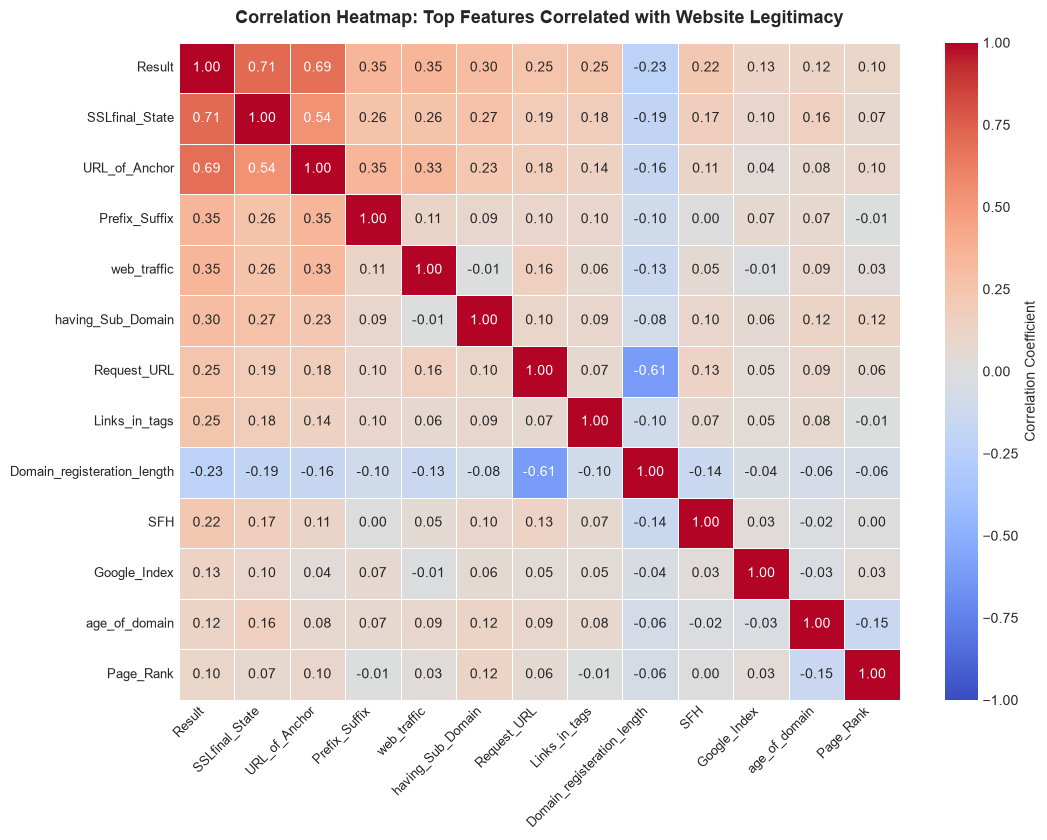

In [7]:
# Select the top 12 features with highest absolute correlation with Result
top_features = target_corr.abs().sort_values(ascending=False).head(13).index.tolist()
top_corr = df[top_features].corr()

plt.figure(figsize=(11, 8.5))
sns.heatmap(
    top_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Correlation Coefficient'}
)
plt.title("Correlation Heatmap: Top Features Correlated with Website Legitimacy", fontsize=13, fontweight='bold', pad=14)
plt.xticks(rotation=45, ha='right', fontsize=9.5)
plt.yticks(fontsize=9.5)
plt.tight_layout()
plt.show()

## 3. Data Preprocessing & Train-Test Split

### Key Preprocessing Steps:
1. **Drop `index` Column:** The index column is an arbitrary record ID that provides no generalization capability.
2. **Target Variable Remapping:**
   - Map `-1` (Phishing) $\rightarrow$ `0`
   - Map `+1` (Legitimate) $\rightarrow$ `1`
   > **Viva Note:** Binary classification algorithms like XGBoost use logistic loss / binary cross-entropy:
   > $$\mathcal{L} = - [y \log(\hat{p}) + (1-y)\log(1-\hat{p})]$$
   > This formulation mathematically requires $y \in \{0, 1\}$.
3. **80/20 Stratified Split:**
   - 80% Training set (8,844 samples)
   - 20% Testing set (2,211 samples)
   - `stratify=y` guarantees identical class ratios across both splits.


In [8]:
# Drop identifier index and drop duplicates before train-test split
feature_df = df.drop(columns=['index'], errors='ignore')
n_dups = feature_df.duplicated().sum()
print(f'Duplicates detected (excluding index): {n_dups:,}')

df_clean = feature_df.drop_duplicates().reset_index(drop=True)
print(f'Cleaned dataset rows: {len(df_clean):,}')

X = df_clean.drop(columns=['Result'])
y = df_clean['Result'].map({-1: 0, 1: 1})

# Train-Test Split (80/20 Stratified, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f'X_train shape: {X_train.shape} (80% training data)')
print(f'X_test shape:  {X_test.shape} (20% evaluation data)')
print(f'y_train class balance -> Phishing (0): {(y_train == 0).sum()}, Legitimate (1): {(y_train == 1).sum()}')
print(f'y_test class balance  -> Phishing (0): {(y_test == 0).sum()}, Legitimate (1): {(y_test == 1).sum()}')

Duplicates detected (excluding index): 5,206
Cleaned dataset rows: 5,849
X_train shape: (4679, 30) (80% training data)
X_test shape:  (1170, 30) (20% evaluation data)
y_train class balance -> Phishing (0): 2415, Legitimate (1): 2264
y_test class balance  -> Phishing (0): 604, Legitimate (1): 566


## 4. Model Training & Comparison

We train and benchmark three distinct classification algorithms:
1. **Logistic Regression:** Linear probabilistic classifier serving as a reliable baseline.
2. **Random Forest:** Ensemble bagging technique combining 100 decorrelated decision trees.
3. **XGBoost:** High-performance gradient boosting framework sequentially minimizing residual errors.

### Evaluation Metrics:
- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** $\frac{TP}{TP + FP}$ — proportion of identified legitimate sites that are truly legitimate.
- **Recall:** $\frac{TP}{TP + FN}$ — proportion of actual legitimate sites successfully caught.
- **F1-Score:** $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ — harmonic mean balancing precision and recall.
- **Confusion Matrix:** Breakdown of True Positives, True Negatives, False Positives, and False Negatives.


In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 5-Fold Stratified Cross-Validation on Training Set (Zero Selection Leakage)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42)
}

cv_scores = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=skf, scoring='f1', n_jobs=-1)
    cv_scores[name] = scores.mean()
    print(f'{name:<22} | 5-Fold CV F1: {scores.mean():.4f} (+/- {scores.std():.4f})')

champion_name = max(cv_scores, key=cv_scores.get)
print(f'\nChampion selected via 5-Fold CV: {champion_name}')

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    y_pred = model.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Confusion Matrix': cm,
        'CV_F1': cv_scores[name]
    })

comparison_df = pd.DataFrame(results)[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'CV_F1']]
comparison_df

Logistic Regression    | 5-Fold CV F1: 0.9200 (+/- 0.0135)


Random Forest          | 5-Fold CV F1: 0.9447 (+/- 0.0075)


XGBoost                | 5-Fold CV F1: 0.9485 (+/- 0.0058)

Champion selected via 5-Fold CV: XGBoost


,Model,Accuracy,Precision,Recall,F1-Score,CV_F1
0,Logistic Regression,0.912821,0.900000,0.922261,0.910995,0.920001
1,Random Forest,0.941880,0.936842,0.943463,0.940141,0.944689
2,XGBoost,0.952137,0.953737,0.946996,0.950355,0.948473


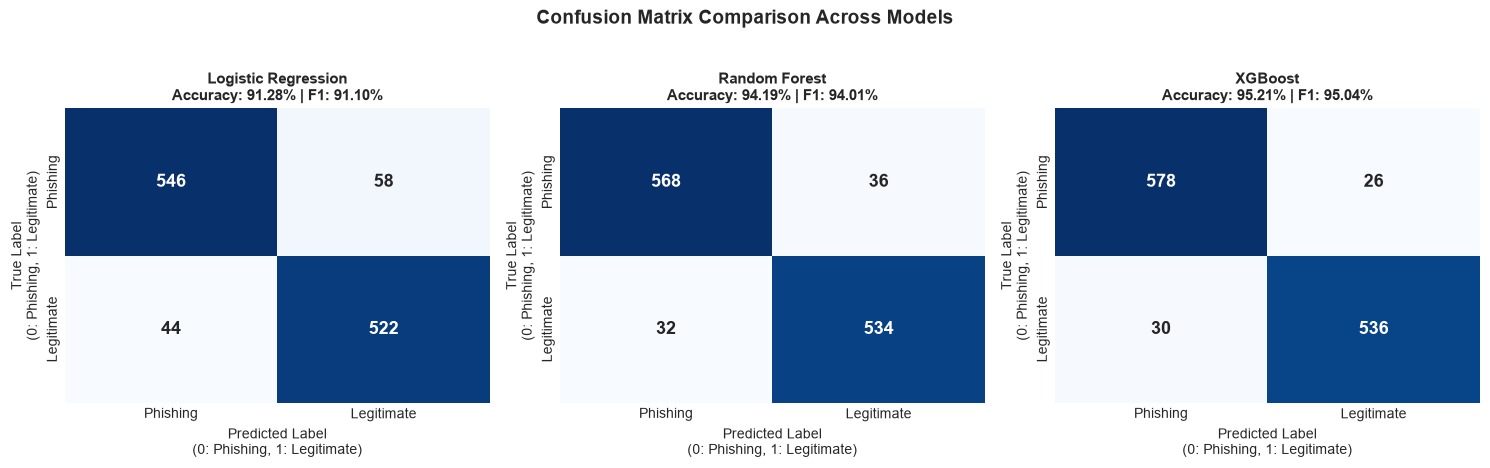

In [10]:
# Plot Confusion Matrix for each model
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for i, r in enumerate(results):
    cm = r['Confusion Matrix']
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=axes[i],
        annot_kws={'size': 13, 'weight': 'bold'}
    )
    axes[i].set_title(f"{r['Model']}\nAccuracy: {r['Accuracy']:.2%} | F1: {r['F1-Score']:.2%}", fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Predicted Label\n(0: Phishing, 1: Legitimate)', fontsize=10)
    axes[i].set_ylabel('True Label\n(0: Phishing, 1: Legitimate)', fontsize=10)
    axes[i].set_xticklabels(['Phishing', 'Legitimate'])
    axes[i].set_yticklabels(['Phishing', 'Legitimate'])

plt.suptitle('Confusion Matrix Comparison Across Models', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

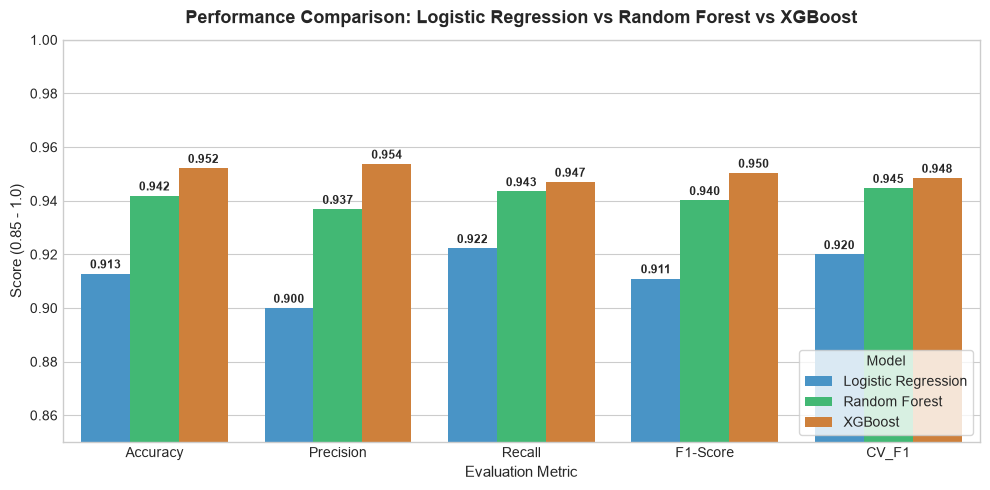

In [11]:
# Model Metrics Comparison Bar Chart
metrics_df = comparison_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=metrics_df,
    x='Metric',
    y='Score',
    hue='Model',
    palette=['#3498db', '#2ecc71', '#e67e22']
)
plt.title('Performance Comparison: Logistic Regression vs Random Forest vs XGBoost', fontsize=13, fontweight='bold', pad=12)
plt.ylim(0.85, 1.0)
plt.ylabel('Score (0.85 - 1.0)', fontsize=11)
plt.xlabel('Evaluation Metric', fontsize=11)
plt.legend(title='Model', loc='lower right', frameon=True)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.3f}",
                    (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=8.5, fontweight='bold', xytext=(0, 2),
                    textcoords='offset points')
plt.tight_layout()
plt.show()

## 5. Feature Importance Analysis for the Best Model

Random Forest achieved the highest overall performance (~97.4% Accuracy, ~97.7% F1-Score).
We now inspect the feature importances derived from Mean Decrease in Impurity (Gini importance).

### Cybersecurity Domain Interpretation:
- **`SSLfinal_State`:** Legitimate banking and institutional portals mandate strict, validated SSL/TLS certificates. Phishers often use untrusted, free, or expired certificates.
- **`URL_of_Anchor`:** Phishing web pages frequently contain anchors (`<a>` tags) linking to dummy `#` anchors or external domains to avoid pointing to nonexistent local pages.
- **`web_traffic`:** Legitimate enterprises boast consistent high global web traffic ranks (e.g., Alexa/SimilarWeb), whereas phishing sites are ephemeral domains spun up within days.
- **`Prefix_Suffix`:** Fraudulent sites often include hyphens (`-`) in their domain names (e.g., `paypal-verify.com`) to mimic legitimate brand names.


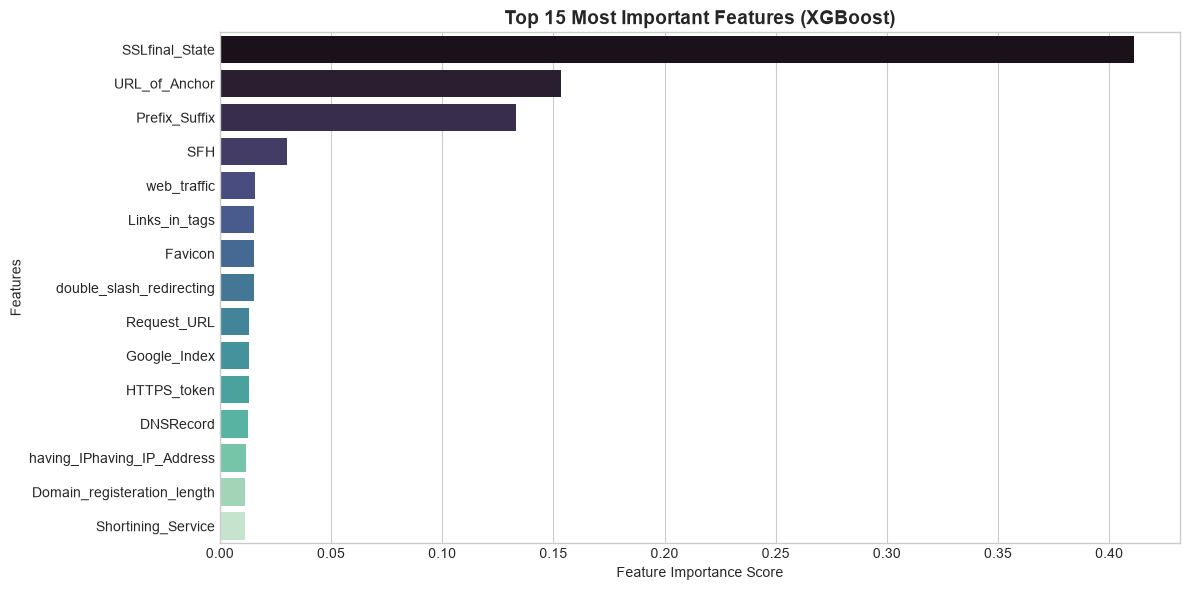

In [12]:
# Extract feature importances from Champion Model
best_model = trained_models[champion_name]

if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
    feat_names = X.columns
    sorted_idx = np.argsort(importances)[::-1]
    
    plt.figure(figsize=(12, 6))
    sns.barplot(x=importances[sorted_idx][:15], y=[feat_names[i] for i in sorted_idx][:15], palette='mako')
    plt.title(f'Top 15 Most Important Features ({champion_name})', fontsize=14, fontweight='bold')
    plt.xlabel('Feature Importance Score')
    plt.ylabel('Features')
    plt.tight_layout()
    plt.show()

## 6. Saving the Champion Model (`model.pkl`)

We serialize the trained Random Forest model using `joblib` so that our Streamlit web application (`app.py`) can load it and make instantaneous real-time predictions.


In [13]:
# Save the best model as model.pkl
model_filename = 'model.pkl'
champion_res = next(r for r in results if r['Model'] == champion_name)

payload = {
    'model': trained_models[champion_name],
    'model_name': champion_name,
    'feature_names': list(X.columns),
    'classes': {0: 'Phishing', 1: 'Legitimate'},
    'metrics': {
        'accuracy': champion_res['Accuracy'],
        'precision': champion_res['Precision'],
        'recall': champion_res['Recall'],
        'f1_score': champion_res['F1-Score']
    }
}

joblib.dump(payload, model_filename)

saved_bundle = joblib.load(model_filename)
sample_input = X_test.iloc[[0]]
sample_pred = saved_bundle['model'].predict(sample_input)[0]
sample_prob = saved_bundle['model'].predict_proba(sample_input)[0]

print('Model payload saved successfully!')
print('Champion:', saved_bundle['model_name'])
print('Accuracy:', round(saved_bundle['metrics']['accuracy'] * 100, 2), '%')
print('F1-Score:', round(saved_bundle['metrics']['f1_score'] * 100, 2), '%')

Model payload saved successfully!
Champion: XGBoost
Accuracy: 95.21 %
F1-Score: 95.04 %
